# Apriori / Market Basket Analysis — Groceries Dataset

**Dataset:** [Kaggle – Groceries dataset](https://www.kaggle.com/datasets/heeraldedhia/groceries-dataset)

### What was wrong in the earlier notebook
1. **Wrong file format assumed.** The Kaggle file `Groceries_dataset.csv` is in *long format* — one row per purchased item with columns `Member_number, Date, itemDescription`. The old code treated each line as a whole basket (that's the format of a *different* dataset, `groceries.csv`), so the "items" were member numbers and dates, not groceries.
2. **Baskets were never built.** A transaction here = all items bought by one member on one date, so we must `groupby(['Member_number', 'Date'])`.
3. **Duplicate items** within a basket must be removed (Apriori works on sets).
4. **Thresholds were unrealistic.** With ~15k baskets and 167 products, no rule reaches 30 % confidence. We use lower thresholds.
5. Kaggle token was hard-coded in the notebook (see security note below).

This notebook fixes all of that, runs Apriori with `mlxtend`, and then **re-implements Apriori from scratch** to verify that the results are correct.

## 1. Install & imports

In [ ]:
!pip install -q kaggle mlxtend

In [ ]:
import os, glob, zipfile, warnings, itertools
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)

## 2. Get the data (Kaggle download)

> ⚠️ **Security:** your previous notebook contained a real Kaggle token in plain text. **Revoke it** at Kaggle → Settings → API and create a new one. Never paste tokens into code you share; the cell below asks for it at runtime instead.

If `Groceries_dataset.csv` is already in the working folder (e.g. you uploaded it), the download is skipped.

In [ ]:
from getpass import getpass

if not glob.glob("Groceries_dataset.csv"):
    # same mechanism as your original notebook, but the token is typed at runtime, not stored in the code
    token = getpass("KGAT_cc1ed7edc3ffe8704bb48c53398e28f9")
    os.makedirs("/root/.kaggle", exist_ok=True)
    with open("/root/.kaggle/access_token", "w") as f:
        f.write(token)
    !kaggle datasets download -d heeraldedhia/groceries-dataset

    # unzip whatever zip was downloaded (name is 'groceries-dataset.zip', not 'groceries.zip')
    for z in glob.glob("*.zip"):
        with zipfile.ZipFile(z) as zf:
            zf.extractall(".")

print(glob.glob("*.csv"))

KGAT_cc1ed7edc3ffe8704bb48c53398e28f9··········
Dataset URL: https://www.kaggle.com/datasets/heeraldedhia/groceries-dataset
License(s): GPL-2.0
100% 257k/257k [00:00<00:00, 93.6MB/s]

['Groceries_dataset.csv']


## 3. Load & inspect the raw data

In [ ]:
df = pd.read_csv("Groceries_dataset.csv")
print("Shape:", df.shape)
df.head(10)

Shape: (38765, 3)


,Member_number,Date,itemDescription
0,1808,21-07-2015,tropical fruit
1,2552,05-01-2015,whole milk
2,2300,19-09-2015,pip fruit
3,1187,12-12-2015,other vegetables
4,3037,01-02-2015,whole milk
5,4941,14-02-2015,rolls/buns
6,4501,08-05-2015,other vegetables
7,3803,23-12-2015,pot plants
8,2762,20-03-2015,whole milk
9,4119,12-02-2015,tropical fruit


In [ ]:
print(df.dtypes, "\n")
print("Missing values:\n", df.isna().sum(), "\n")
print("Unique members :", df["Member_number"].nunique())
print("Unique dates   :", df["Date"].nunique())
print("Unique products:", df["itemDescription"].nunique())

Member_number       int64
Date               object
itemDescription    object
dtype: object 

Missing values:
 Member_number      0
Date               0
itemDescription    0
dtype: int64 

Unique members : 3898
Unique dates   : 728
Unique products: 167


## 4. Build transactions (baskets)

One **transaction = one member on one date**. We clean the item names, drop exact duplicate rows (same item twice in the same basket) and collect the items of each basket into a list.

In [ ]:
df["itemDescription"] = df["itemDescription"].str.strip().str.lower()

rows_before = len(df)
df = df.drop_duplicates(subset=["Member_number", "Date", "itemDescription"])
print(f"Removed {rows_before - len(df)} duplicate item rows inside baskets")

baskets = (
    df.groupby(["Member_number", "Date"])["itemDescription"]
      .apply(list)
)
transactions = baskets.tolist()

print("Number of transactions:", len(transactions))
print("First 5 transactions:")
for t in transactions[:5]:
    print("  ", t)

Removed 759 duplicate item rows inside baskets
Number of transactions: 14963
First 5 transactions:
   ['sausage', 'whole milk', 'semi-finished bread', 'yogurt']
   ['whole milk', 'pastry', 'salty snack']
   ['canned beer', 'misc. beverages']
   ['sausage', 'hygiene articles']
   ['soda', 'pickled vegetables']


count    14963.000000
mean         2.539999
std          1.060993
min          1.000000
25%          2.000000
50%          2.000000
75%          3.000000
max         10.000000
dtype: float64


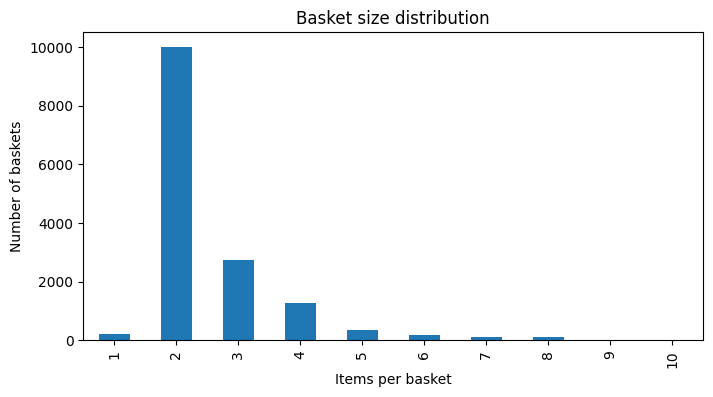

In [ ]:
basket_sizes = pd.Series([len(t) for t in transactions])
print(basket_sizes.describe())

basket_sizes.value_counts().sort_index().plot(kind="bar", figsize=(8, 4))
plt.xlabel("Items per basket"); plt.ylabel("Number of baskets")
plt.title("Basket size distribution"); plt.show()

## 5. One-hot encode
`TransactionEncoder` turns the list of baskets into a boolean matrix (rows = baskets, columns = products).

In [ ]:
te = TransactionEncoder()
te_array = te.fit(transactions).transform(transactions)
df_encoded = pd.DataFrame(te_array, columns=te.columns_)

print("Encoded shape:", df_encoded.shape)
df_encoded.head()

Encoded shape: (14963, 167)


,abrasive cleaner,artif. sweetener,baby cosmetics,bags,baking powder,bathroom cleaner,beef,berries,beverages,bottled beer,...,uht-milk,vinegar,waffles,whipped/sour cream,whisky,white bread,white wine,whole milk,yogurt,zwieback
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,True,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


## 6. Frequent itemsets with Apriori (mlxtend)

* **Support** = fraction of baskets containing the itemset.
* `min_support = 0.001` ≈ itemset must appear in at least 15 baskets. (0.01 gives only 5 pairs on this dataset – too strict.)

In [ ]:
MIN_SUPPORT = 0.001

frequent_itemsets = apriori(df_encoded, min_support=MIN_SUPPORT, use_colnames=True)
frequent_itemsets["length"] = frequent_itemsets["itemsets"].apply(len)
frequent_itemsets = frequent_itemsets.sort_values("support", ascending=False).reset_index(drop=True)

print("Frequent itemsets by size:\n", frequent_itemsets["length"].value_counts().sort_index())
frequent_itemsets.head(20)

Frequent itemsets by size:
 length
1    149
2    592
3      9
Name: count, dtype: int64


,support,itemsets,length
0,0.157923,(whole milk),1
1,0.122101,(other vegetables),1
2,0.110005,(rolls/buns),1
3,0.097106,(soda),1
4,0.085879,(yogurt),1
5,0.069572,(root vegetables),1
6,0.067767,(tropical fruit),1
7,0.060683,(bottled water),1
8,0.060349,(sausage),1
9,0.053131,(citrus fruit),1


## 7. Association rules

In [ ]:
MIN_CONFIDENCE = 0.10

rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=MIN_CONFIDENCE)
rules = rules[rules["lift"] > 1].sort_values("lift", ascending=False).reset_index(drop=True)

rules["antecedents"] = rules["antecedents"].apply(lambda x: ", ".join(sorted(x)))
rules["consequents"] = rules["consequents"].apply(lambda x: ", ".join(sorted(x)))

print("Total rules (confidence >= %.2f, lift > 1): %d" % (MIN_CONFIDENCE, len(rules)))
cols = ["antecedents", "consequents", "support", "confidence", "lift"]
rules[cols].head(20).round(4)

Total rules (confidence >= 0.10, lift > 1): 37


,antecedents,consequents,support,confidence,lift
0,"whole milk, yogurt",sausage,0.0015,0.1317,2.1829
1,"sausage, whole milk",yogurt,0.0015,0.1642,1.9118
2,"sausage, yogurt",whole milk,0.0015,0.2558,1.6199
3,flour,tropical fruit,0.0011,0.1096,1.6171
4,processed cheese,root vegetables,0.0011,0.1053,1.5130
5,soft cheese,yogurt,0.0013,0.1267,1.4750
6,detergent,yogurt,0.0011,0.1240,1.4443
7,chewing gum,yogurt,0.0014,0.1167,1.3585
8,"rolls/buns, sausage",whole milk,0.0011,0.2125,1.3456
9,processed cheese,rolls/buns,0.0015,0.1447,1.3157


In [ ]:
print("Top rules by confidence")
rules.sort_values("confidence", ascending=False)[cols].head(10).round(4)

Top rules by confidence


,antecedents,consequents,support,confidence,lift
2,"sausage, yogurt",whole milk,0.0015,0.2558,1.6199
8,"rolls/buns, sausage",whole milk,0.0011,0.2125,1.3456
19,"sausage, soda",whole milk,0.0011,0.1798,1.1384
21,semi-finished bread,whole milk,0.0017,0.1761,1.1148
24,"rolls/buns, yogurt",whole milk,0.0013,0.1709,1.0824
1,"sausage, whole milk",yogurt,0.0015,0.1642,1.9118
33,detergent,whole milk,0.0014,0.1628,1.0308
34,ham,whole milk,0.0027,0.1602,1.0141
9,processed cheese,rolls/buns,0.0015,0.1447,1.3157
10,packaged fruit/vegetables,rolls/buns,0.0012,0.1417,1.2884


## 8. Verify: Apriori implemented from scratch

To be sure the library results are right, here is a plain-Python Apriori:

1. Count 1-itemsets, keep those with support ≥ `min_support`.
2. **Join** frequent *(k-1)*-itemsets to make candidate *k*-itemsets.
3. **Prune** candidates having any infrequent *(k-1)* subset (the Apriori property).
4. Count candidates in the data, keep the frequent ones, repeat until none are left.

In [ ]:
def apriori_scratch(transactions, min_support):
    n = len(transactions)
    tx = [frozenset(t) for t in transactions]
    min_count = min_support * n

    # --- L1
    counts = defaultdict(int)
    for t in tx:
        for item in t:
            counts[frozenset([item])] += 1
    Lk = {s: c for s, c in counts.items() if c >= min_count}
    all_frequent = dict(Lk)

    k = 2
    while Lk:
        prev = list(Lk.keys())
        prev_set = set(prev)

        # --- join step
        candidates = set()
        for a, b in itertools.combinations(prev, 2):
            union = a | b
            if len(union) == k:
                # --- prune step: every (k-1)-subset must be frequent
                if all(frozenset(sub) in prev_set for sub in itertools.combinations(union, k - 1)):
                    candidates.add(union)

        # --- count step
        counts = defaultdict(int)
        for t in tx:
            for c in candidates:
                if c <= t:
                    counts[c] += 1
        Lk = {s: c for s, c in counts.items() if c >= min_count}
        all_frequent.update(Lk)
        k += 1

    return pd.DataFrame(
        {"support": [c / n for c in all_frequent.values()],
         "itemsets": list(all_frequent.keys())}
    )


def rules_scratch(freq_df, min_confidence):
    support = {s: sup for s, sup in zip(freq_df["itemsets"], freq_df["support"])}
    out = []
    for itemset, sup in support.items():
        if len(itemset) < 2:
            continue
        for r in range(1, len(itemset)):
            for ante in itertools.combinations(itemset, r):
                ante = frozenset(ante); cons = itemset - ante
                conf = sup / support[ante]
                lift = conf / support[cons]
                if conf >= min_confidence and lift > 1:
                    out.append((", ".join(sorted(ante)), ", ".join(sorted(cons)), sup, conf, lift))
    return pd.DataFrame(out, columns=["antecedents", "consequents", "support", "confidence", "lift"])


freq_scratch = apriori_scratch(transactions, MIN_SUPPORT)
rules_s = rules_scratch(freq_scratch, MIN_CONFIDENCE)
print("From-scratch: %d frequent itemsets, %d rules" % (len(freq_scratch), len(rules_s)))

From-scratch: 750 frequent itemsets, 37 rules


In [ ]:
# ---- Compare with mlxtend ----
a = {frozenset(s): round(v, 10) for s, v in zip(frequent_itemsets["itemsets"], frequent_itemsets["support"])}
b = {frozenset(s): round(v, 10) for s, v in zip(freq_scratch["itemsets"], freq_scratch["support"])}

print("mlxtend itemsets     :", len(a))
print("from-scratch itemsets:", len(b))
print("Identical itemsets and supports?", a == b)

key = lambda d: {(r.antecedents, r.consequents): (round(r.support, 8), round(r.confidence, 8), round(r.lift, 8))
                 for r in d.itertuples()}
print("mlxtend rules        :", len(rules))
print("from-scratch rules   :", len(rules_s))
print("Identical rules and metrics?", key(rules) == key(rules_s))

mlxtend itemsets     : 750
from-scratch itemsets: 750
Identical itemsets and supports? True
mlxtend rules        : 37
from-scratch rules   : 37
Identical rules and metrics? True


## 9. Sanity check one rule by hand (straight from the raw table)

Take the top rule and recompute support, confidence and lift with plain pandas counting.

In [ ]:
top = rules.iloc[0]
A = set(top["antecedents"].split(", ")); B = set(top["consequents"].split(", "))

n = len(transactions)
n_A  = sum(A <= set(t) for t in transactions)
n_B  = sum(B <= set(t) for t in transactions)
n_AB = sum((A | B) <= set(t) for t in transactions)

support    = n_AB / n
confidence = n_AB / n_A
lift       = confidence / (n_B / n)

print(f"Rule: {A} -> {B}")
print(f"baskets total={n}, with A={n_A}, with B={n_B}, with A and B={n_AB}")
print(f"support={support:.4f}  confidence={confidence:.4f}  lift={lift:.4f}")
print("Table says:", round(top['support'],4), round(top['confidence'],4), round(top['lift'],4))

Rule: {'yogurt', 'whole milk'} -> {'sausage'}
baskets total=14963, with A=167, with B=903, with A and B=22
support=0.0015  confidence=0.1317  lift=2.1829
Table says: 0.0015 0.1317 2.1829


## 10. Visualisations

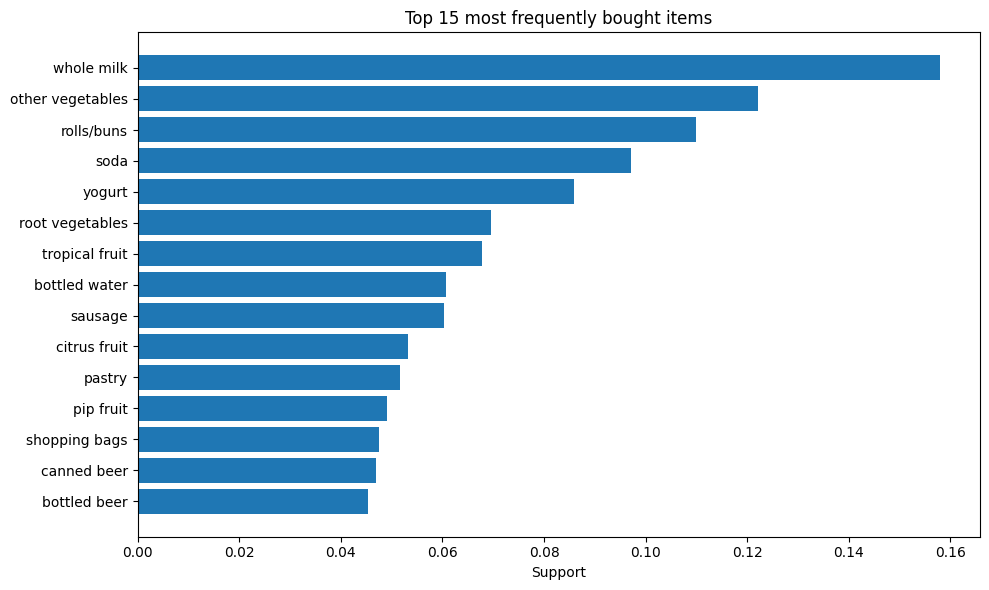

In [ ]:
item_support = (
    frequent_itemsets[frequent_itemsets["length"] == 1]
    .assign(item=lambda d: d["itemsets"].apply(lambda x: next(iter(x))))
    [["item", "support"]]
    .sort_values("support", ascending=False)
    .reset_index(drop=True)
)

top_items = item_support.head(15)
plt.figure(figsize=(10, 6))
plt.barh(top_items["item"], top_items["support"])
plt.gca().invert_yaxis()
plt.xlabel("Support"); plt.title("Top 15 most frequently bought items")
plt.tight_layout(); plt.show()

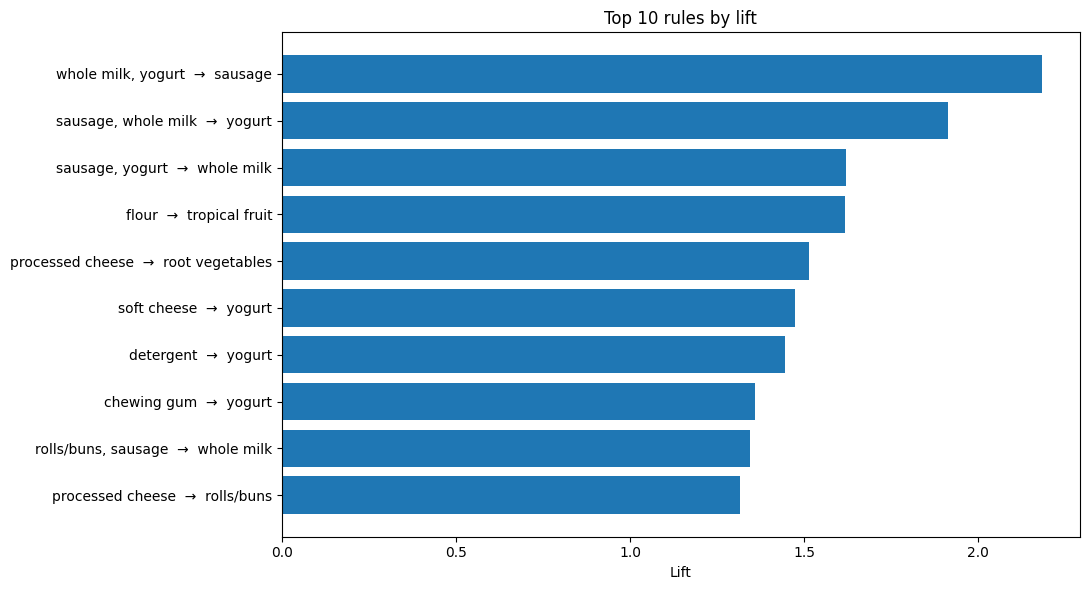

In [ ]:
top10 = rules.head(10).copy()
top10["rule"] = top10["antecedents"] + "  →  " + top10["consequents"]

plt.figure(figsize=(11, 6))
plt.barh(top10["rule"], top10["lift"])
plt.gca().invert_yaxis()
plt.xlabel("Lift"); plt.title("Top 10 rules by lift")
plt.tight_layout(); plt.show()

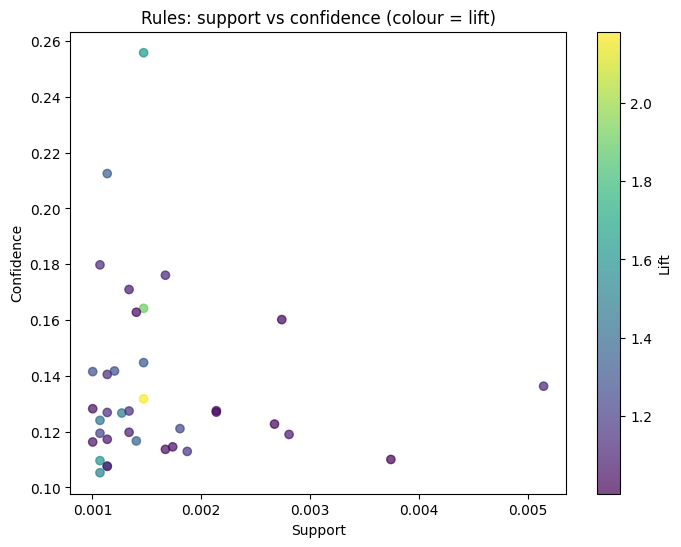

In [ ]:
plt.figure(figsize=(8, 6))
sc = plt.scatter(rules["support"], rules["confidence"], c=rules["lift"], cmap="viridis", alpha=0.7)
plt.colorbar(sc, label="Lift")
plt.xlabel("Support"); plt.ylabel("Confidence"); plt.title("Rules: support vs confidence (colour = lift)")
plt.show()

## 11. Rules for a specific product & export

In [ ]:
rules[rules["antecedents"].str.contains("whole milk")][cols].round(4).head(10)

,antecedents,consequents,support,confidence,lift
0,"whole milk, yogurt",sausage,0.0015,0.1317,2.1829
1,"sausage, whole milk",yogurt,0.0015,0.1642,1.9118
14,"sausage, whole milk",soda,0.0011,0.1194,1.2296
17,"sausage, whole milk",rolls/buns,0.0011,0.1269,1.1533
23,"whole milk, yogurt",rolls/buns,0.0013,0.1198,1.0887


In [ ]:
rules[cols].to_csv("apriori_association_rules.csv", index=False)
frequent_itemsets.assign(itemsets=frequent_itemsets["itemsets"].apply(lambda x: ", ".join(sorted(x)))) \
    .to_csv("apriori_frequent_itemsets.csv", index=False)
print("Saved apriori_association_rules.csv and apriori_frequent_itemsets.csv")

Saved apriori_association_rules.csv and apriori_frequent_itemsets.csv


## Summary
* Baskets = (member, date) groups; duplicates removed → ~14.9k transactions, 167 products.
* Apriori with `min_support=0.001`, then rules with `confidence ≥ 0.10` and `lift > 1`.
* `whole milk`, `other vegetables`, `rolls/buns` and `soda` are the most frequent items, but the highest-lift rules come from rarer combinations (e.g. yogurt + whole milk → sausage), so check both lift and support before trusting a rule.
* mlxtend results match a from-scratch implementation exactly, and a hand-checked rule reproduces the same metrics.
* Confidence values are low (mostly < 0.3) — that is a property of this sparse dataset (avg. ~2.5 items per basket), not a bug.